# Case bootstrap of the final structure

The bootstrap asks how much the estimates of the free parameters move when the data set is different. It resamples the **conditions** (cases) with replacement, not the residuals: the 22 conditions are the independent experimental units, and the weighted objective is a sum over them.

* resample $r = 1,\dots,N_\text{boot}$ ($N_\text{boot} = 1000$, seed 0): draw 22 conditions with replacement (a condition can appear several times, others not at all);
* refit the selected structure on the resample, **warm started at the final point** (theta and the primal point of each condition) with the tight monotone options; a failed fit is retried once with a monotone barrier (`retry_monotone`);
* summarise the $\hat\theta^*_r$: percentiles, CV, the fraction of resamples on a theta bound, and the objective of each resample.

A parameter is called **practically identifiable** by the bootstrap if it is not parked (see the caveat) and all three hold (`settings/uncertainty.csv`): the 97.5/2.5 percentile ratio is at most 10 (`bootstrap_ci_ratio_max`), less than 5% of the resamples sit on a theta bound (`bootstrap_frac_at_bound_max`), and the log-span of the interval is less than half the log-span of the theta bounds (`bootstrap_ci_span_max`).

**Bias-corrected (BC) interval** (used in the figures): with $z_0 = \Phi^{-1}\big(\#\{\hat\theta^*_r < \hat\theta\}/N\big)$ the 95% interval is the percentile interval between $\Phi(2 z_0 + z_{0.025})$ and $\Phi(2 z_0 + z_{0.975})$; the *confidence coefficient* is its width divided by the estimate.

**Objective of the resamples.** Because the hardest conditions dominate the objective, the objective of a resample depends on how often they are drawn. The summary regresses it on the number of copies of KO18 and KO05, $\text{obj} \approx c_0 + c_1\,n_{KO18} + c_2\,n_{KO05}$.

**Parked parameters.** A warm-started refit of a parameter the data cannot move never leaves its start: the bootstrap median then equals the anchor (relative distance below `bootstrap_parked_rtol` = 1e-6) and the interval is narrow, but this is parking, not information. Such a parameter is marked `parked` and reported as **not practically identifiable**. It stays in the free set only because the rules always keep it free (`kept_free_by_rule`: the $k_\mathrm{cat}$ of every reaction and the last free parameter of each rate law carry the biology of the reaction), not because the data identify it. Compare with the profile likelihood (`profiles.ipynb`) as well.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json
import pickle

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from settings import RUN as RUN_SETTINGS, default_params
from uncertainty import bootstrap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

FINAL = os.path.join(OUT, "final")
BOOT = os.path.join(OUT, "bootstrap")
N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))
RESUME = os.environ.get("HK_RESUME", "0") == "1"

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : False (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. Run (`HK_RUN=1`)

`bootstrap.run_bootstrap(anchor_dir, out_dir, params, resume)` reads `OUT/final/anchor_state.pkl` (written by `final_fit.ipynb`), fits the resamples in chunks (a checkpoint `bootstrap_theta.csv` after every chunk, `HK_RESUME=1` continues from it) and writes `bootstrap_resamples.csv` (the conditions of every resample), `bootstrap_theta.csv`, `bootstrap_summary.csv`, `objective_by_n_KO18.csv`, `bootstrap_info.json` and a copy of the anchor state into `OUT/bootstrap/`. The settings are the dict `params` below (defaults from `settings/uncertainty.csv`); switches: `HK_N_JOBS`, `HK_RESUME`.

In [2]:
# Settings of the bootstrap (defaults from settings/uncertainty.csv)
params = default_params("bootstrap")
params["bootstrap_n"] = 1000             # number of resamples
params["bootstrap_seed"] = 0             # seed of the resampling
params["bootstrap_ci_ratio_max"] = 10.0  # practically identifiable: 97.5 / 2.5 percentile ratio at most this
params["n_jobs"] = N_JOBS                # worker processes (HK_N_JOBS)
params

{'n_jobs': 8,
 'theta_at_bound_tol': 0.01,
 'bootstrap_n': 1000,
 'bootstrap_chunk': 100,
 'bootstrap_seed': 0,
 'bootstrap_ci_ratio_max': 10.0,
 'bootstrap_frac_at_bound_max': 0.05,
 'bootstrap_ci_span_max': 0.5,
 'bootstrap_parked_rtol': 1e-06}

In [3]:
if RUN:
    bootstrap.run_bootstrap(FINAL, BOOT, params, resume=RESUME)
else:
    print("RUN is False: the bootstrap is loaded from", BOOT)

RUN is False: the bootstrap is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model/bootstrap


In [4]:
# a finished fit without its summary (e.g. an interrupted run): summarise what is saved
if (not os.path.exists(os.path.join(BOOT, "bootstrap_summary.csv"))) and os.path.exists(os.path.join(BOOT, "bootstrap_theta.csv")) and WRITABLE:
    bootstrap.summarize_saved(FINAL, BOOT, params)

## 2. Summary

In [5]:
boot_info = json.load(open(os.path.join(BOOT, "bootstrap_info.json"))) if os.path.exists(os.path.join(BOOT, "bootstrap_info.json")) else None
summary = pd.read_csv(os.path.join(BOOT, "bootstrap_summary.csv"), index_col=0) if os.path.exists(os.path.join(BOOT, "bootstrap_summary.csv")) else None

if boot_info is not None:
    print("%d resamples, %d converged (%d needed the monotone retry), %d failed" % (
        boot_info["n_resamples"], boot_info["n_converged"], boot_info["n_retried_ok"], boot_info["n_failed"]))
    print("objective: anchor %.3f, bootstrap median %.3f, 95%% [%.2f, %.2f]" % (
        boot_info["obj_anchor"], boot_info["obj_boot_median"], *boot_info["obj_boot_p2.5_p97.5"]))
    print("objective ~ %.2f + %.2f n_KO18 + %.2f n_KO05 (R2 %.2f)" % (
        boot_info["obj_regression_intercept"], boot_info["obj_per_KO18_copy"], boot_info["obj_per_KO05_copy"], boot_info["obj_regression_R2"]))
    print("practically identifiable: %d of %d free parameters" % (boot_info["n_practically_identifiable"], boot_info["n_free"]))
    print("parked at the warm start (not identifiable, kept free by rule):", ", ".join(boot_info["parked"]))
else:
    print("bootstrap_info.json not found: run the bootstrap first")

summary

1000 resamples, 1000 converged (10 needed the monotone retry), 0 failed
objective: anchor 10.943, bootstrap median 10.486, 95% [2.93, 23.94]
objective ~ 2.96 + 6.68 n_KO18 + 1.43 n_KO05 (R2 0.49)
practically identifiable: 1 of 11 free parameters
parked at the warm start (not identifiable, kept free by rule): K_g6p_1, kcat_f_5, kcat_f_6, kcat_f_7, kcat_f_8


,anchor,mean,median,p2.5,p97.5,sd,cv_percent,sd_log10,ci_ratio_97.5_over_2.5,frac_at_theta_bound,anchor_inside_ci,log_bounds_span_decades,ci_span_over_bounds_span,parked,kept_free_by_rule,practically_identifiable
param,,,,,,,,,,,,,,,,
K_g6p_1,10.001076,10.001190,10.001076,10.000520,10.002312,0.000602,0.006017,0.000026,1.000179,0.000,True,4.30103,0.000018,True,True,False
Ks_g6p_pgi,0.197194,0.755449,0.181659,0.001390,4.191992,1.287683,170.452669,1.156037,3016.032974,0.000,True,4.30103,0.808977,False,False,False
kcat_f_2,917.423639,859.994413,915.472853,495.942925,999.507169,146.425639,17.026348,0.089050,2.015367,0.146,True,4.00000,0.076089,False,True,False
kcat_f_3,960.087926,922.060336,959.402366,742.287108,999.961266,79.438887,8.615368,0.039522,1.347135,0.221,True,4.00000,0.032353,False,True,False
Ks_fbp_4,0.001002,0.148449,0.001002,0.001001,0.001080,1.604070,1080.552828,0.411376,1.078950,0.970,True,4.30103,0.007673,False,False,False
kcat_f_4,2.699551,7.346625,2.711753,2.456360,3.112851,47.738558,649.802561,0.222114,1.267262,0.000,True,4.00000,0.025717,False,True,True
kcat_f_5,5578.920937,5975.146137,5578.920965,5266.629416,9151.707034,1049.674120,17.567338,0.065203,1.737678,0.000,True,2.30103,0.104288,True,True,False
kcat_f_6,537.757240,575.994430,537.757256,512.073198,903.521127,104.547521,18.150787,0.066376,1.764437,0.000,True,4.00000,0.061652,True,True,False
kcat_f_7,720.523954,737.748490,720.524031,580.086243,991.417534,105.948380,14.361043,0.059131,1.709086,0.038,True,4.00000,0.058191,True,True,False


## 3. Resamples and BC intervals

In [6]:
theta_path = os.path.join(BOOT, "bootstrap_theta.csv")
resamples_path = os.path.join(BOOT, "bootstrap_resamples.csv")
state_path = os.path.join(FINAL, "anchor_state.pkl")

if os.path.exists(theta_path) and os.path.exists(resamples_path) and os.path.exists(state_path):
    boot = pd.read_csv(theta_path)
    boot = boot[boot["converged"]].reset_index(drop=True)
    resamples = pd.read_csv(resamples_path).set_index("resample")
    state = pickle.load(open(state_path, "rb"))
    free = list(state["free"])
    boot["n_KO18"] = [names.split(";").count("KO18") for names in resamples.loc[boot["resample"], "conditions"]]

    rows = []
    for p in free:
        tb = boot[p].to_numpy(float)
        theta_hat = float(state["theta"][p])
        z0 = scipy.stats.norm.ppf(np.clip(np.mean(tb < theta_hat), 1e-12, 1 - 1e-12))
        lo = np.percentile(tb, 100 * scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.025)))
        hi = np.percentile(tb, 100 * scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.975)))
        rows.append({"param": p, "anchor": theta_hat, "BC_lo": lo, "BC_hi": hi, "confidence_coefficient": (hi - lo) / theta_hat})
    bc = pd.DataFrame(rows).set_index("param")
    print("%d converged resamples" % len(boot))
    display(bc)
else:
    boot = None
    print("bootstrap files or the final anchor state not found")

1000 converged resamples


,anchor,BC_lo,BC_hi,confidence_coefficient
param,,,,
K_g6p_1,10.001076,10.000512,10.002190,0.000168
Ks_g6p_pgi,0.197194,0.001459,5.136478,26.040480
kcat_f_2,917.423639,501.159115,999.773858,0.543495
kcat_f_3,960.087926,743.381431,999.962379,0.267247
Ks_fbp_4,0.001002,0.001001,0.001631,0.629024
kcat_f_4,2.699551,2.442426,3.077204,0.235142
kcat_f_5,5578.920937,5156.267361,9010.385080,0.690836
kcat_f_6,537.757240,510.705326,894.557945,0.713803
kcat_f_7,720.523954,570.761790,990.757378,0.582903


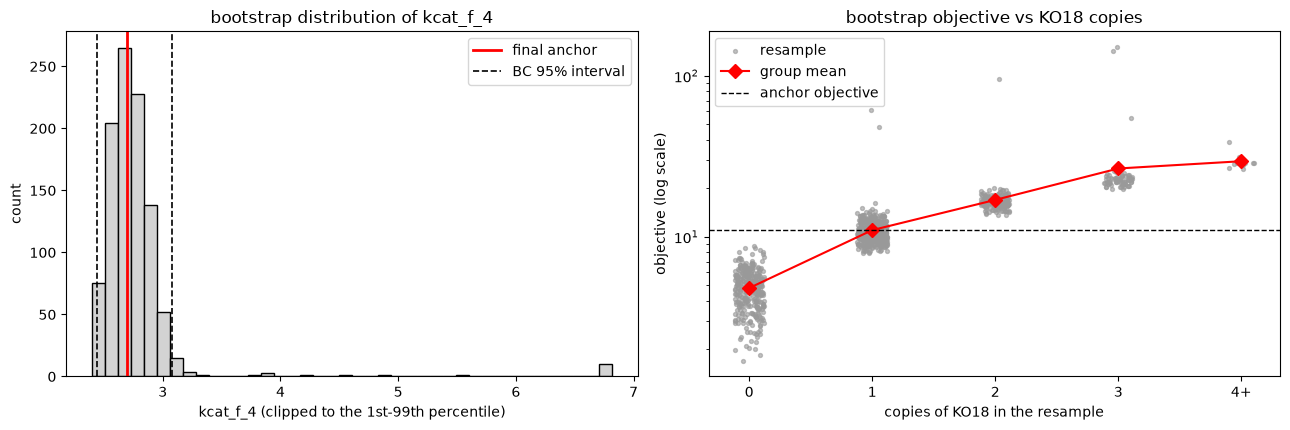

In [7]:
if boot is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    ax_k4, ax_obj = axes

    # kcat_f_4: the identifiable parameter (histogram clipped to the 1st-99th percentile)
    if "kcat_f_4" in boot.columns:
        k4 = boot["kcat_f_4"].to_numpy(float)
        lo, hi = np.percentile(k4, [1, 99])
        ax_k4.hist(np.clip(k4, lo, hi), bins=np.linspace(lo, hi, 41), color="lightgrey", edgecolor="black")
        ax_k4.axvline(float(state["theta"]["kcat_f_4"]), color="red", lw=2, label="final anchor")
        ax_k4.axvline(bc.loc["kcat_f_4", "BC_lo"], color="black", ls="--", lw=1.2, label="BC 95% interval")
        ax_k4.axvline(bc.loc["kcat_f_4", "BC_hi"], color="black", ls="--", lw=1.2)
        ax_k4.set_xlabel("kcat_f_4 (clipped to the 1st-99th percentile)")
        ax_k4.set_ylabel("count")
        ax_k4.legend()
        ax_k4.set_title("bootstrap distribution of kcat_f_4")

    # objective of the resamples against the number of KO18 copies
    group = boot["n_KO18"].clip(upper=4)
    jitter = group.to_numpy() + np.random.default_rng(0).uniform(-0.12, 0.12, len(boot))
    ax_obj.scatter(jitter, boot["obj"], s=8, color="0.6", alpha=0.6, label="resample")
    means = boot.groupby(group)["obj"].mean()
    ax_obj.plot(means.index.to_numpy(), means.to_numpy(), "D-", color="red", ms=7, label="group mean")
    ax_obj.axhline(float(state["obj"]), color="black", ls="--", lw=1, label="anchor objective")
    ax_obj.set_yscale("log")
    ax_obj.set_xticks([0, 1, 2, 3, 4])
    ax_obj.set_xticklabels(["0", "1", "2", "3", "4+"])
    ax_obj.set_xlabel("copies of KO18 in the resample")
    ax_obj.set_ylabel("objective (log scale)")
    ax_obj.legend()
    ax_obj.set_title("bootstrap objective vs KO18 copies")

    fig.tight_layout()
    plt.show()

### Parameter by parameter

For every free parameter: where the bootstrap median lies relative to the anchor, the CV, and the three practical-identifiability criteria. The bars show the ratio $\hat\theta^*_{97.5}/\hat\theta^*_{2.5}$ on a log scale against the allowed ratio of 10; bars at 1 are parameters the resampling could not move at all (parked, orange): they are not practically identifiable.

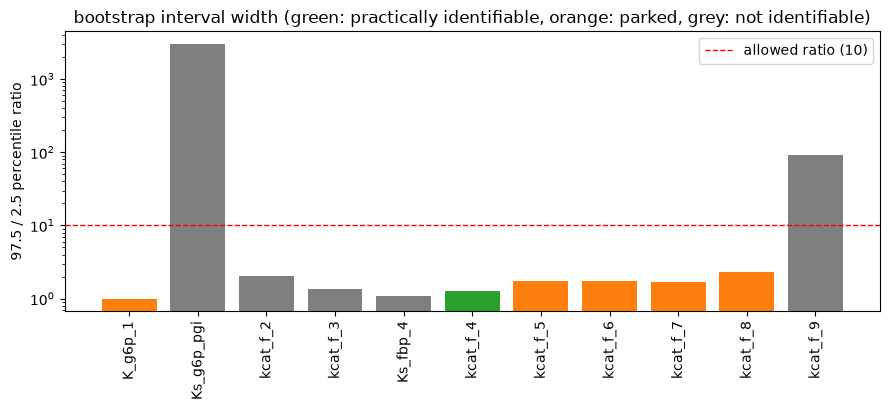

,anchor,median,cv_percent,frac_at_theta_bound,ci_span_over_bounds_span,parked,kept_free_by_rule,practically_identifiable
param,,,,,,,,
K_g6p_1,10.001076,10.001076,0.006017,0.000,0.000018,True,True,False
Ks_g6p_pgi,0.197194,0.181659,170.452669,0.000,0.808977,False,False,False
kcat_f_2,917.423639,915.472853,17.026348,0.146,0.076089,False,True,False
kcat_f_3,960.087926,959.402366,8.615368,0.221,0.032353,False,True,False
Ks_fbp_4,0.001002,0.001002,1080.552828,0.970,0.007673,False,False,False
kcat_f_4,2.699551,2.711753,649.802561,0.000,0.025717,False,True,True
kcat_f_5,5578.920937,5578.920965,17.567338,0.000,0.104288,True,True,False
kcat_f_6,537.757240,537.757256,18.150787,0.000,0.061652,True,True,False
kcat_f_7,720.523954,720.524031,14.361043,0.038,0.058191,True,True,False


In [8]:
if summary is not None:
    fig, ax = plt.subplots(figsize=(9, 4.2))
    x = np.arange(len(summary))
    colors = []
    for name in summary.index:
        if summary.loc[name, "practically_identifiable"]:
            colors.append("tab:green")
        elif summary.loc[name, "parked"]:
            colors.append("tab:orange")
        else:
            colors.append("tab:grey")
    ax.bar(x, summary["ci_ratio_97.5_over_2.5"], color=colors)
    ax.axhline(params["bootstrap_ci_ratio_max"], color="red", ls="--", lw=1, label="allowed ratio (%.0f)" % params["bootstrap_ci_ratio_max"])
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(summary.index, rotation=90)
    ax.set_ylabel("97.5 / 2.5 percentile ratio")
    ax.legend()
    ax.set_title("bootstrap interval width (green: practically identifiable, orange: parked, grey: not identifiable)")
    fig.tight_layout()
    plt.show()
    display(summary[["anchor", "median", "cv_percent", "frac_at_theta_bound", "ci_span_over_bounds_span", "parked", "kept_free_by_rule", "practically_identifiable"]])

### Objective against the hard conditions

`objective_by_n_KO18.csv`: count, mean and standard deviation of the resample objective by number of KO18 copies. The regression of section 2 attributes most of the spread to KO18.

In [9]:
by_k = pd.read_csv(os.path.join(BOOT, "objective_by_n_KO18.csv"), index_col=0) if os.path.exists(os.path.join(BOOT, "objective_by_n_KO18.csv")) else None
by_k

,count,mean,std
n_KO18,,,
0,308,4.803108,1.373922
1,427,10.993704,3.340625
2,187,16.940767,5.934210
3,68,26.549408,21.540392
4,9,28.431689,1.413441
6,1,38.680444,NaN
